# Лабораторная работа №1: arXiv HTML

## 1. Получение примеров

Метаданные я получаю через [arXiv API](https://export.arxiv.org/api/query), а сырой документ — с HTML-страницы статьи. Сохраняются название, авторы, аннотация, категории, даты и лицензия. Выборка содержит по 10 статей из категорий `cs.IR`, `cs.AI` и `cs.CL` — всего 30 документов. HTML загружается последовательно с паузой 1 секунда; при ответах `429` и `503` применяется отдельная длительная пауза. Примеры кэшируются в каталоге `notebooks/samples`.

In [1]:
from pathlib import Path
import json
import re
import time
import xml.etree.ElementTree as ET

from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import pandas as pd
import requests

API_URL = 'https://export.arxiv.org/api/query'
HTML_URL = 'https://arxiv.org/html/{arxiv_id}'
SAMPLE_CATEGORIES = ['cs.IR', 'cs.AI', 'cs.CL']
DOCUMENTS_PER_CATEGORY = 10
SAMPLE_SIZE = len(SAMPLE_CATEGORIES) * DOCUMENTS_PER_CATEGORY
HTML_REQUEST_DELAY = 1
DATA_DIR = Path('samples')
SAMPLE_FILE = DATA_DIR / 'arxiv_sample.json'
DATA_DIR.mkdir(exist_ok=True)

session = requests.Session()
session.headers['User-Agent'] = 'MAI-IR-course-project/1.0 (educational corpus analysis)'

In [2]:
ATOM = '{http://www.w3.org/2005/Atom}'
ARXIV = '{http://arxiv.org/schemas/atom}'

def parse_api_entries(xml_text):
    root = ET.fromstring(xml_text)
    result = []
    for entry in root.findall(f'{ATOM}entry'):
        identifier = entry.findtext(f'{ATOM}id').rstrip('/').split('/')[-1]
        license_node = entry.find(f'{ARXIV}license')
        result.append({
            'arxiv_id': identifier,
            'title': re.sub(r'\s+', ' ', entry.findtext(f'{ATOM}title')).strip(),
            'abstract': re.sub(r'\s+', ' ', entry.findtext(f'{ATOM}summary')).strip(),
            'authors': [node.findtext(f'{ATOM}name') for node in entry.findall(f'{ATOM}author')],
            'categories': [node.attrib['term'] for node in entry.findall(f'{ATOM}category')],
            'published': entry.findtext(f'{ATOM}published'),
            'updated': entry.findtext(f'{ATOM}updated'),
            'license': license_node.text if license_node is not None else None,
        })
    return result

def get_with_retries(url, *, params=None, timeout=60, attempts=5):
    for attempt in range(attempts):
        response = session.get(url, params=params, timeout=timeout)
        if response.status_code not in (429, 503):
            response.raise_for_status()
            return response
        if attempt < attempts - 1:
            retry_after = response.headers.get('Retry-After', '')
            wait_seconds = int(retry_after) if retry_after.isdigit() else 30
            time.sleep(wait_seconds)
    response.raise_for_status()

def download_arxiv_sample(existing_documents=None):
    documents = list(existing_documents or [])
    seen_ids = {document['arxiv_id'] for document in documents}
    html_requested = False
    for category in SAMPLE_CATEGORIES:
        category_documents = sum(
            document['sample_category'] == category for document in documents
        )
        if category_documents >= DOCUMENTS_PER_CATEGORY:
            continue
        response = get_with_retries(API_URL, params={
            'search_query': f'cat:{category}',
            'start': 0, 'max_results': 30,
            'sortBy': 'submittedDate', 'sortOrder': 'descending',
        })

        for metadata in parse_api_entries(response.text):
            if metadata['arxiv_id'] in seen_ids:
                continue
            if html_requested:
                time.sleep(HTML_REQUEST_DELAY)
            url = HTML_URL.format(arxiv_id=metadata['arxiv_id'])
            try:
                html_response = get_with_retries(url)
            except requests.RequestException:
                continue
            html_requested = True
            documents.append({
                **metadata, 'sample_category': category,
                'url': url, 'html': html_response.text,
            })
            seen_ids.add(metadata['arxiv_id'])
            category_documents += 1
            if category_documents == DOCUMENTS_PER_CATEGORY:
                break
        if len(documents) == SAMPLE_SIZE:
            return documents
    return documents

raw_documents = (
    json.loads(SAMPLE_FILE.read_text(encoding='utf-8'))
    if SAMPLE_FILE.exists() else []
)
if len(raw_documents) < SAMPLE_SIZE:
    raw_documents = download_arxiv_sample(raw_documents)
    SAMPLE_FILE.write_text(json.dumps(raw_documents, ensure_ascii=False, indent=2), encoding='utf-8')

print(f'Скачано документов: {len(raw_documents)}')
print(f'Файл с примерами: {SAMPLE_FILE}')

Скачано документов: 30
Файл с примерами: samples/arxiv_sample.json


## 2. Выделение текста и метаданных

В HTML статьи основной текст расположен в элементе `article`. Я удаляю скрипты, стили и навигационные элементы, после чего объединяю текстовые блоки. Формулы остаются в текстовом представлении, но их исходная двумерная структура частично теряется.

In [3]:
def extract_article_text(html):
    soup = BeautifulSoup(html, 'lxml')
    article = soup.select_one('article.ltx_document, article, main')
    if article is None:
        return ''
    for node in article.select('script, style, nav, aside, footer'):
        node.decompose()
    blocks = [node.get_text(' ', strip=True) for node in article.select('h1, h2, h3, p, li, pre')]
    return re.sub(r'\s+', ' ', ' '.join(blocks)).strip()

documents = []
for raw in raw_documents:
    text = extract_article_text(raw['html'])
    documents.append({
        'source_id': raw['arxiv_id'],
        'sample_category': raw['sample_category'],
        'title': raw['title'],
        'url': raw['url'],
        'authors': raw['authors'],
        'categories': raw['categories'],
        'published': raw['published'],
        'license': raw['license'],
        'text': text,
        'raw_size': len(raw['html'].encode('utf-8')),
        'text_size': len(text.encode('utf-8')),
        'word_count': len(text.split()),
    })

frame = pd.DataFrame(documents)
frame[['source_id', 'sample_category', 'title', 'categories', 'word_count', 'raw_size', 'text_size']]

,source_id,sample_category,title,categories,word_count,raw_size,text_size
0,2610.28569v1,cs.IR,ECHO: Efficient Cascade with Homogeneous Opera...,[cs.IR],9958,298752,65419
1,2610.28632v1,cs.AI,"Joints, Camera, Action! Co-Generating 3D Motio...","[cs.CV, cs.AI, cs.GR, cs.LG, cs.RO]",13687,301121,83973
2,2610.28616v1,cs.CL,NarraSpace: Multimodal Scene-Grounded Evidence...,[cs.CL],13112,460250,93239
3,2610.28568v1,cs.IR,Evolving Semantic Indexes for Generative Retri...,"[cs.AI, cs.IR, cs.LG]",7722,1003494,48776
4,2610.28435v1,cs.IR,Multimodal Reranking Is a System One Decision,[cs.IR],5806,393967,36089
5,2610.28340v1,cs.IR,DeclineCraft: A RAG Abstention Benchmark for J...,"[cs.CL, cs.IR]",19722,697208,124921
6,2610.28054v1,cs.IR,AutoSim: A Self-Improving User Simulator for C...,[cs.IR],8267,242768,50016
7,2610.27898v1,cs.IR,SPAR: Stepwise Personalized Autoregressive Rec...,[cs.IR],6810,248872,45200
8,2610.27850v1,cs.IR,Robustness Analysis of Pareto-based Joint Eval...,[cs.IR],29262,1277791,168834
9,2610.27829v1,cs.IR,GARRET: Generative Feedback for Region Retriev...,"[cs.CV, cs.IR]",11882,430862,77842


## 3. Статистика выборки

In [4]:
statistics = pd.Series({
    'Количество документов': len(frame),
    'Размер сырых документов, байт': int(frame.raw_size.sum()),
    'Размер выделенного текста, байт': int(frame.text_size.sum()),
    'Средний размер сырого документа, байт': round(frame.raw_size.mean(), 2),
    'Средний размер текста, байт': round(frame.text_size.mean(), 2),
    'Среднее количество слов': round(frame.word_count.mean(), 2),
})
statistics

Количество документов                          30.00
Размер сырых документов, байт            16108664.00
Размер выделенного текста, байт           2242943.00
Средний размер сырого документа, байт      536955.47
Средний размер текста, байт                 74764.77
Среднее количество слов                     11931.97
dtype: float64

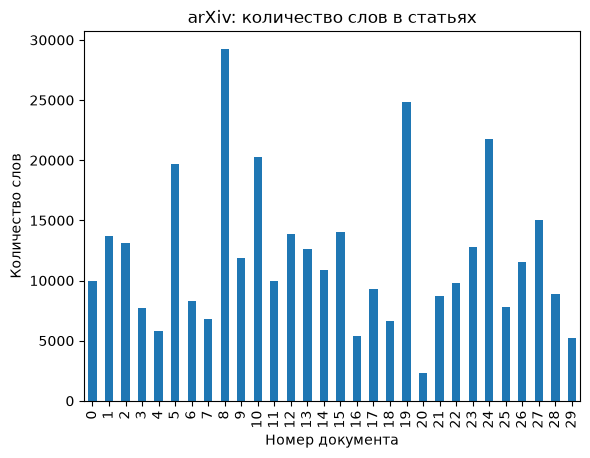

In [5]:
frame.word_count.plot.bar(title='arXiv: количество слов в статьях')
plt.xlabel('Номер документа')
plt.ylabel('Количество слов')
plt.show()

## 4. Существующий поиск

Примеры запросов: [neural information retrieval](https://arxiv.org/search/?query=%22neural+information+retrieval%22&searchtype=all) и [vector database](https://arxiv.org/search/?query=%22vector+database%22&searchtype=all).

| Запрос | Наблюдение | Недостаток |
|---|---|---|
| `neural information retrieval` | Находятся профильные научные публикации | Выдача не содержит практическую документацию и справочные статьи |
| `vector database` | Находятся работы о векторном поиске и индексах | Короткий запрос даёт тематически близкие статьи, которые не всегда отвечают на практический вопрос |

Поиск arXiv хорошо работает с названиями, авторами и научной терминологией. Дополнительное ограничение источника: HTML доступен не для каждой статьи.

## Вывод

arXiv добавляет в корпус длинные научные тексты, формулы и точные предметные категории. Источник полезен для проверки поиска по сложной научной терминологии.